# Курсова робота: дослідження та підготовка даних для розв'язання задачі машинного навчання**Предметна область:** криптовалютний ринок.**Задача:** для монети, що торгується на Binance, спрогнозувати на моментзакриття тижня, чи випередить вона за дохідністю медіанну монету ринкупротягом наступних семи днів.Пашко Назарій, СА-32, Львів-2026.

## 1. Імпорти, налаштування, SEED

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu, pointbiserialr, skew, spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("SEED =", SEED)

SEED = 42


## 2. Завантаження сирих данихСирий датасет зібрано самостійно скриптом `data/raw/build_weekly_panel.py`з денної історії Binance (OHLCV) і довідників CoinGecko. Одиницяспостереження - монета в конкретний тиждень; момент прогнозу - закриттяторгів у неділю; горизонт - наступні сім днів.

In [2]:
RAW_PATH = "data/raw/raw_crypto_weekly_panel.csv.gz"
df_raw = pd.read_csv(RAW_PATH, parse_dates=["checkpoint"])

print("Розмір сирого датасету:", df_raw.shape)
print("Період:", df_raw["checkpoint"].min().date(), "-", df_raw["checkpoint"].max().date())
print("Унікальних монет:", df_raw["symbol"].nunique())
print("Унікальних тижнів:", df_raw["checkpoint"].nunique())
print("Монет на тиждень: від", df_raw.groupby("checkpoint").size().min(),
      "до", df_raw.groupby("checkpoint").size().max())

Розмір сирого датасету: (65820, 33)
Період: 2021-01-03 - 2026-09-13
Унікальних монет: 384
Унікальних тижнів: 298
Монет на тиждень: від 85 до 384


## 3. Початкове технічне профілювання

In [3]:
print("Стовпців:", len(df_raw.columns))
print()
print(df_raw.dtypes.to_string())

Стовпців: 33

symbol                                     str
coingecko_id                               str
checkpoint                      datetime64[us]
sector                                     str
market_regime                              str
close_t0                               float64
trailing_return_7d                     float64
trailing_return_30d                    float64
trailing_return_90d                    float64
trailing_volatility_7d                 float64
trailing_volatility_30d                float64
avg_quote_volume_30d                   float64
trailing_volume_trend                  float64
volume_7d_vs_30d                       float64
drawdown_from_high_180d                float64
max_daily_return_30d                   float64
rsi_14                                 float64
macd_hist_norm                         float64
bollinger_pctb_20                      float64
btc_corr_90d                           float64
btc_beta_90d                           float64

In [4]:
profile = pd.DataFrame({
    "тип": df_raw.dtypes.astype(str),
    "пропусків": df_raw.isna().sum(),
    "пропусків, %": (df_raw.isna().mean() * 100).round(2),
    "унікальних": df_raw.nunique(),
})
profile

,тип,пропусків,"пропусків, %",унікальних
symbol,str,0,0.00,384
coingecko_id,str,0,0.00,384
checkpoint,datetime64[us],0,0.00,298
sector,str,10508,15.96,15
market_regime,str,0,0.00,3
close_t0,float64,0,0.00,30817
trailing_return_7d,float64,0,0.00,62055
trailing_return_30d,float64,0,0.00,63730
trailing_return_90d,float64,0,0.00,64531
trailing_volatility_7d,float64,0,0.00,65798


In [5]:
print("Точних дублікатів рядків:", int(df_raw.duplicated().sum()))
print("Дублікатів пари (symbol, checkpoint):",
      int(df_raw.duplicated(subset=["symbol", "checkpoint"]).sum()))

const_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) <= 1]
print("Константних стовпців:", const_cols if const_cols else "немає")

print()
print("Розподіл цільової змінної beat_market:")
print(df_raw["beat_market"].value_counts(normalize=True).round(4).to_string())
print("Пропусків у цілі:", int(df_raw["beat_market"].isna().sum()))

Точних дублікатів рядків: 0
Дублікатів пари (symbol, checkpoint): 0
Константних стовпців: немає

Розподіл цільової змінної beat_market:
beat_market
0    0.5011
1    0.4989
Пропусків у цілі: 0


In [6]:
checks = pd.DataFrame([
    {"правило": "rsi_14 в межах 0-100",
     "порушень": int(((df_raw["rsi_14"] < 0) | (df_raw["rsi_14"] > 100)).sum())},
    {"правило": "волатильність невід'ємна",
     "порушень": int((df_raw["trailing_volatility_30d"] < 0).sum())},
    {"правило": "обсяг торгів невід'ємний",
     "порушень": int((df_raw["avg_quote_volume_30d"] < 0).sum())},
    {"правило": "вік монети не менший за 98 днів",
     "порушень": int((df_raw["coin_age_days"] < 98).sum())},
    {"правило": "дохідність не менша за -100 %",
     "порушень": int((df_raw["forward_return"] < -1).sum())},
    {"правило": "просадка в межах -100..0 %",
     "порушень": int(((df_raw["drawdown_from_high_180d"] < -1)
                      | (df_raw["drawdown_from_high_180d"] > 0)).sum())},
    {"правило": "усі числові значення скінченні",
     "порушень": int((~np.isfinite(df_raw.select_dtypes("number"))).sum().sum()
                     - df_raw.select_dtypes("number").isna().sum().sum())},
])
checks

,правило,порушень
0,rsi_14 в межах 0-100,0
1,волатильність невід'ємна,0
2,обсяг торгів невід'ємний,0
3,вік монети не менший за 98 днів,0
4,дохідність не менша за -100 %,0
5,просадка в межах -100..0 %,0
6,усі числові значення скінченні,0


## 4. Структурне очищення

In [7]:
join_audit = pd.read_csv("data/join_audit_weekly.csv")
print("Символів Binance усього:", len(join_audit))
print(join_audit["status"].value_counts().to_string())
print()
unresolved = join_audit[join_audit["status"] == "unresolved_no_cgid"]
print("Не зіставлено з CoinGecko (виключені ще на етапі побудови панелі):", len(unresolved))
print(unresolved["symbol"].head(15).tolist())

Символів Binance усього: 485
status
resolved              353
resolved_no_sector     77
unresolved_no_cgid     55

Не зіставлено з CoinGecko (виключені ще на етапі побудови панелі): 55
['1000CATUSDT', '1000CHEEMSUSDT', '1000SATSUSDT', '1MBABYDOGEUSDT', 'ACHUSDT', 'AGPUBUSDT', 'AIGENSYNUSDT', 'ALABBUSDT', 'AMCBUSDT', 'ASTSBUSDT', 'BBUSDT', 'BEAMXUSDT', 'BNSOLUSDT', 'BROCCOLI714USDT', 'BTTCUSDT']


In [8]:
df_clean = df_raw.copy()

before_sector = int(df_clean["sector"].isna().sum())
df_clean["sector"] = df_clean["sector"].fillna("Other")
before_rows = len(df_clean)
df_clean = df_clean[df_clean["beat_market"].notna()].copy()
dropped_target = before_rows - len(df_clean)
df_clean["checkpoint"] = pd.to_datetime(df_clean["checkpoint"])
df_clean["symbol"] = df_clean["symbol"].str.upper().str.strip()

cleaning_log = pd.DataFrame([
    {"проблема": "sector відсутній (монета поза 20 куратованими секторами)",
     "виявлення": "df['sector'].isna()",
     "дія": "позначено явною категорією 'Other'",
     "записів": before_sector,
     "обґрунтування": "відсутність мітки - це стан 'нема куратованої категорії', "
                      "а не помилка вимірювання; статистичні параметри не оцінюються"},
    {"проблема": "невідоме значення цільової змінної",
     "виявлення": "df['beat_market'].isna()",
     "дія": "рядки вилучено до поділу train/test",
     "записів": dropped_target,
     "обґрунтування": "ціль не імпутується; рядок без цілі непридатний для навчання"},
    {"проблема": "символи Binance без зіставлення з CoinGecko",
     "виявлення": "join_audit.status == 'unresolved_no_cgid'",
     "дія": "виключено на етапі побудови панелі",
     "записів": len(unresolved),
     "обґрунтування": "неможливо ані визначити сектор, ані підтвердити, що це криптовалюта"},
    {"проблема": "регістр і пробіли в ідентифікаторі монети",
     "виявлення": "порівняння symbol з його нормалізованою формою",
     "дія": "уніфіковано верхній регістр без пробілів",
     "записів": 0,
     "обґрунтування": "детерміноване форматування, не потребує статистики"},
])
cleaning_log

,проблема,виявлення,дія,записів,обґрунтування
0,sector відсутній (монета поза 20 куратованими ...,df['sector'].isna(),позначено явною категорією 'Other',10508,відсутність мітки - це стан 'нема куратованої ...
1,невідоме значення цільової змінної,df['beat_market'].isna(),рядки вилучено до поділу train/test,0,ціль не імпутується; рядок без цілі непридатни...
2,символи Binance без зіставлення з CoinGecko,join_audit.status == 'unresolved_no_cgid',виключено на етапі побудови панелі,55,"неможливо ані визначити сектор, ані підтвердит..."
3,регістр і пробіли в ідентифікаторі монети,порівняння symbol з його нормалізованою формою,уніфіковано верхній регістр без пробілів,0,"детерміноване форматування, не потребує статис..."


In [9]:
print("Пропусків sector після очищення:", int(df_clean["sector"].isna().sum()))
print("Точних дублікатів:", int(df_clean.duplicated().sum()))
print("Рядків до / після очищення:", len(df_raw), "/", len(df_clean))
print("Типи стовпців збережено:", (df_clean.dtypes.astype(str) == df_raw.dtypes.astype(str)).all())
print("Пропусків у цілі:", int(df_clean["beat_market"].isna().sum()))
print()
print("Розподіл секторів після очищення:")
print(df_clean["sector"].value_counts().to_string())

Пропусків sector після очищення: 0
Точних дублікатів: 0
Рядків до / після очищення: 65820 / 65820
Типи стовпців збережено: True
Пропусків у цілі: 0

Розподіл секторів після очищення:
sector
Layer-1             12908
Other               10508
DeFi                 7271
AI                   6237
DEX                  5522
Gaming               5431
Layer-2              3850
Meme                 3055
RWA                  2994
Oracle/Infra         2257
NFT                  1853
Infrastructure       1839
Privacy               858
Exchange Token        513
Stablecoin            444
Metaverse/Gaming      280


In [10]:
df_clean.to_csv("data/structurally_cleaned/structurally_cleaned_weekly_panel.csv.gz",
                index=False, compression="gzip", encoding="utf-8")
print("Збережено: data/structurally_cleaned/structurally_cleaned_weekly_panel.csv.gz")
print("Пропуски, що свідомо залишені для оброблення в конвеєрі:")
na = df_clean.isna().sum()
print(na[na > 0].to_string())

Збережено: data/structurally_cleaned/structurally_cleaned_weekly_panel.csv.gz
Пропуски, що свідомо залишені для оброблення в конвеєрі:
avg_quote_volume_30d     26
trailing_volume_trend    34
volume_7d_vs_30d         32


## 5. Формування train і testДані одночасно часові й групові: та сама монета спостерігається в багатьохтижнях. Тому застосовано часовий поділ без перемішування: межу обрано так,щоб у train потрапило 80 % рядків, а всі тижні train передували всім тижнямtest.

In [11]:
rows_per_week = df_clean.groupby("checkpoint").size().sort_index()
share_cum = rows_per_week.cumsum() / len(df_clean)
n_train_weeks = int((share_cum < 0.80).sum())
weeks = list(rows_per_week.index)
split_week = weeks[n_train_weeks - 1]

train_df = df_clean[df_clean["checkpoint"] <= split_week].reset_index(drop=True)
test_df = df_clean[df_clean["checkpoint"] > split_week].reset_index(drop=True)

print(f"Межа поділу: {split_week.date()}")
print(f"train: {len(train_df)} рядків ({len(train_df)/len(df_clean)*100:.1f} %), "
      f"{train_df['checkpoint'].nunique()} тижнів, "
      f"{train_df['checkpoint'].min().date()} - {train_df['checkpoint'].max().date()}")
print(f"test:  {len(test_df)} рядків ({len(test_df)/len(df_clean)*100:.1f} %), "
      f"{test_df['checkpoint'].nunique()} тижнів, "
      f"{test_df['checkpoint'].min().date()} - {test_df['checkpoint'].max().date()}")

Межа поділу: 2026-01-04
train: 52524 рядків (79.8 %), 262 тижнів, 2021-01-03 - 2026-01-04
test:  13296 рядків (20.2 %), 36 тижнів, 2026-01-11 - 2026-09-13


In [12]:
print("Перетин тижнів між train і test:",
      len(set(train_df["checkpoint"]) & set(test_df["checkpoint"])))
print("Перетин пар (монета, тиждень):",
      len(set(map(tuple, train_df[["symbol", "checkpoint"]].values))
          & set(map(tuple, test_df[["symbol", "checkpoint"]].values))))
print()
print("Частка класу 1 у train:", round(train_df["beat_market"].mean(), 4))
print("Частка класу 1 у test: ", round(test_df["beat_market"].mean(), 4))
print()
print("Ринкові режими за тижнями:")
print(pd.DataFrame({
    "train": train_df.groupby("checkpoint")["market_regime"].first().value_counts(),
    "test": test_df.groupby("checkpoint")["market_regime"].first().value_counts(),
}).fillna(0).astype(int).to_string())

Перетин тижнів між train і test: 0


Перетин пар (монета, тиждень): 0

Частка класу 1 у train: 0.4987
Частка класу 1 у test:  0.4995

Ринкові режими за тижнями:
               train  test
market_regime             
bear              75    25
bull             118     5
sideways          69     6


# Розділ 3. Статистичне дослідження навчальних данихУсі обчислення цього розділу виконуються **тільки на train**.

## 6. Первинне статистичне дослідження train

In [13]:
COIN_FEATURES = [
    "trailing_return_7d", "trailing_return_30d", "trailing_return_90d",
    "trailing_volatility_7d", "trailing_volatility_30d", "avg_quote_volume_30d",
    "trailing_volume_trend", "volume_7d_vs_30d", "drawdown_from_high_180d",
    "max_daily_return_30d", "rsi_14", "macd_hist_norm", "bollinger_pctb_20",
    "btc_corr_90d", "btc_beta_90d", "coin_age_days",
]
MARKET_FEATURES = ["btc_trailing_return_30d", "btc_trailing_return_90d", "btc_rsi_14"]
CAT_FEATURES = ["sector", "market_regime"]

train_df[COIN_FEATURES].describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
trailing_return_7d,52524.0,1.861300e+00,4.255717e+02,-1.0000,-8.360000e-02,-9.300000e-03,6.780000e-02,9.753300e+04
trailing_return_30d,52524.0,2.586900e+00,3.412070e+02,-1.0000,-1.970000e-01,-5.800000e-02,1.212000e-01,5.199900e+04
trailing_return_90d,52524.0,2.138800e+00,2.676535e+02,-1.0000,-3.680000e-01,-1.164000e-01,2.190000e-01,4.104300e+04
trailing_volatility_7d,52524.0,1.327200e+00,2.925655e+02,0.0000,2.920000e-02,4.240000e-02,6.060000e-02,6.705055e+04
trailing_volatility_30d,52524.0,2.521500e+00,2.826368e+02,0.0000,3.690000e-02,4.900000e-02,6.450000e-02,3.238851e+04
avg_quote_volume_30d,52498.0,3.345423e+07,1.462110e+08,33933.6088,1.926398e+06,4.875705e+06,1.680953e+07,4.838468e+09
trailing_volume_trend,52490.0,4.668000e-01,3.097700e+00,-0.9498,-4.293000e-01,-1.403000e-01,4.250000e-01,2.462512e+02
volume_7d_vs_30d,52492.0,5.300000e-03,5.391000e-01,-0.9451,-3.481000e-01,-1.177000e-01,2.076000e-01,3.211100e+00
drawdown_from_high_180d,52524.0,-4.600000e-01,2.259000e-01,-1.0000,-6.372000e-01,-4.825000e-01,-2.902000e-01,0.000000e+00
max_daily_return_30d,52524.0,1.365320e+01,1.548066e+03,0.0000,7.340000e-02,1.077000e-01,1.617000e-01,1.773990e+05


In [14]:
print("Асиметрія числових ознак (train):")
print(train_df[COIN_FEATURES].apply(lambda s: skew(s.dropna())).round(2).sort_values().to_string())
print()
print("Частоти ринкових режимів (рядки train):")
print(train_df["market_regime"].value_counts(normalize=True).round(3).to_string())

Асиметрія числових ознак (train):
macd_hist_norm            -170.74
btc_corr_90d                -0.92
drawdown_from_high_180d      0.23
bollinger_pctb_20            0.33
rsi_14                       0.51
coin_age_days                0.52
volume_7d_vs_30d             1.77
avg_quote_volume_30d        12.63
trailing_volume_trend       22.03
btc_beta_90d                70.55
trailing_volatility_30d    114.58
max_daily_return_30d       114.58
trailing_return_30d        134.95
trailing_return_90d        135.30
trailing_return_7d         229.17
trailing_volatility_7d     229.17

Частоти ринкових режимів (рядки train):
market_regime
bull        0.432
sideways    0.292
bear        0.276


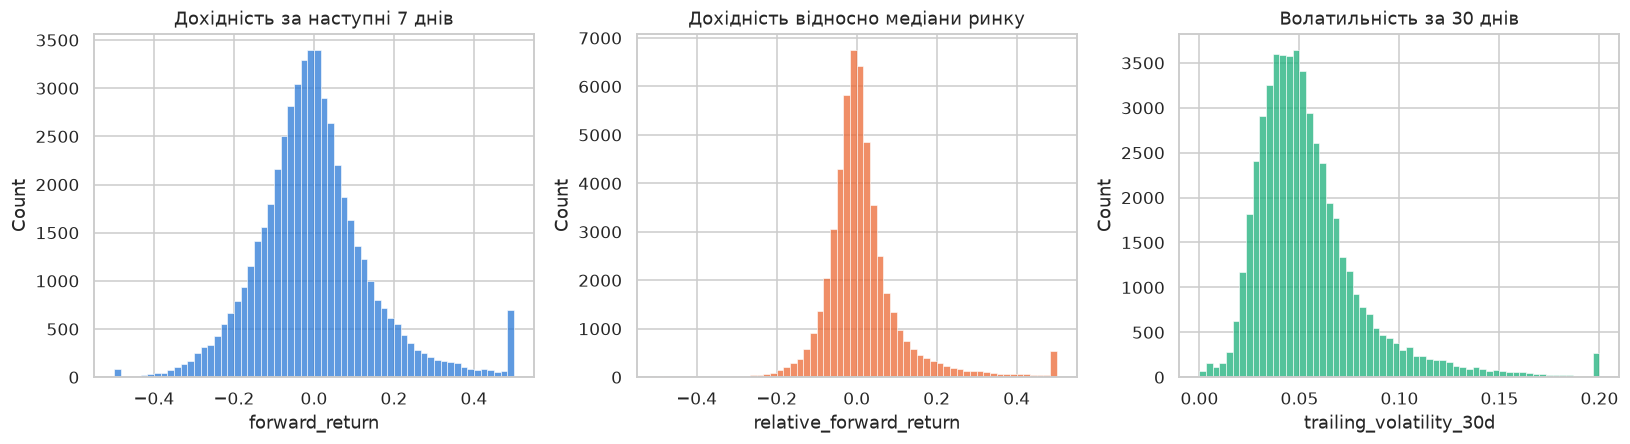

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.histplot(train_df["forward_return"].clip(-0.5, 0.5), bins=60, ax=axes[0], color="#2a78d6")
axes[0].set_title("Дохідність за наступні 7 днів")
axes[0].set_xlabel("forward_return")
sns.histplot(train_df["relative_forward_return"].clip(-0.5, 0.5), bins=60, ax=axes[1],
             color="#eb6834")
axes[1].set_title("Дохідність відносно медіани ринку")
axes[1].set_xlabel("relative_forward_return")
sns.histplot(train_df["trailing_volatility_30d"].clip(0, 0.2), bins=60, ax=axes[2],
             color="#1baf7a")
axes[2].set_title("Волатильність за 30 днів")
axes[2].set_xlabel("trailing_volatility_30d")
plt.tight_layout()
plt.show()

In [16]:
ct = pd.crosstab(train_df["sector"], train_df["beat_market"], normalize="index").mul(100).round(1)
ct.columns = ["не випередила, %", "випередила, %"]
ct["спостережень"] = train_df["sector"].value_counts()
ct.sort_values("випередила, %", ascending=False)

,"не випередила, %","випередила, %",спостережень
sector,,,
Exchange Token,38.8,61.2,441
Stablecoin,43.8,56.2,226
Layer-1,48.3,51.7,10658
Privacy,48.8,51.2,750
Oracle/Infra,48.9,51.1,1883
RWA,49.1,50.9,2381
DEX,49.1,50.9,4526
Other,49.3,50.7,8501
DeFi,50.4,49.6,5724


## 7. Аналіз пропусків

In [17]:
missing = train_df.isna().sum()
missing = missing[missing > 0]
print("Пропуски в train після структурного очищення:")
print(pd.DataFrame({"пропусків": missing,
                    "частка, %": (missing / len(train_df) * 100).round(3)}).to_string())
print()
young = train_df["coin_age_days"] < 130
print("Частка пропусків trailing_volume_trend серед монет віком до 130 днів:",
      round(train_df.loc[young, "trailing_volume_trend"].isna().mean() * 100, 3), "%")
print("Те саме серед монет, старших за 130 днів:",
      round(train_df.loc[~young, "trailing_volume_trend"].isna().mean() * 100, 3), "%")

Пропуски в train після структурного очищення:
                       пропусків  частка, %
avg_quote_volume_30d          26      0.050
trailing_volume_trend         34      0.065
volume_7d_vs_30d              32      0.061

Частка пропусків trailing_volume_trend серед монет віком до 130 днів: 0.0 %
Те саме серед монет, старших за 130 днів: 0.066 %


## 8. Аналіз потенційних викидів

In [18]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


rows = []
for col in ["trailing_return_30d", "trailing_volatility_30d", "max_daily_return_30d",
            "forward_return"]:
    lo, hi = iqr_bounds(train_df[col].dropna())
    out = ((train_df[col] < lo) | (train_df[col] > hi)).sum()
    rows.append({"ознака": col, "нижня межа": round(lo, 4), "верхня межа": round(hi, 4),
                 "за межами": int(out), "частка, %": round(out / len(train_df) * 100, 2)})
pd.DataFrame(rows)

,ознака,нижня межа,верхня межа,за межами,"частка, %"
0,trailing_return_30d,-0.6744,0.5986,3206,6.10
1,trailing_volatility_30d,-0.0045,0.1058,2752,5.24
2,max_daily_return_30d,-0.0592,0.2942,4161,7.92
3,forward_return,-0.3092,0.2929,2650,5.05


In [19]:
extreme = train_df.nlargest(5, "forward_return")[
    ["symbol", "checkpoint", "sector", "trailing_volatility_30d", "forward_return",
     "relative_forward_return"]]
extreme["checkpoint"] = extreme["checkpoint"].dt.date
print("П'ять найбільших значень дохідності за тиждень (train):")
print(extreme.round(3).to_string(index=False))

П'ять найбільших значень дохідності за тиждень (train):
  symbol checkpoint       sector  trailing_volatility_30d  forward_return  relative_forward_return
LUNAUSDT 2022-05-29        Other                    0.297       97533.000                97532.996
 WINUSDT 2021-03-28 Oracle/Infra                    0.095           5.173                    5.015
 CHRUSDT 2021-03-07           AI                    0.117           5.105                    5.002
 CHZUSDT 2021-03-07          NFT                    0.126           4.088                    3.986
MOVRUSDT 2023-12-17      Layer-1                    0.042           4.032                    3.948


## 9. Генеральна сукупність і вибірка**Генеральна сукупність:** усі криптовалюти, що в певний тиждень торгувалисяна публічних біржах, разом з їхньою майбутньою дохідністю.**Вибірка:** 384 монети з парою до USDT на Binance, які торгуються станом навересень 2026 року і мають щонайменше 98 днів історії до відповідного тижня.**Систематичні зміщення.** Вибірка містить лише монети, що дожили до моментузбору даних, тому делістовані та померлі монети відсутні (survivorship bias).Binance також відбирає монети за ліквідністю, тому дрібні активинедопредставлені. Висновки коректно поширювати на ліквідні монети великихбірж, а не на весь крипторинок.

## 10. Статистичні гіпотези### Гіпотеза 1. Волатильність монети пов'язана з її майбутнім результатомH0: розподіл 30-денної волатильності однаковий для монет, які випередилиринок, і тих, які не випередили. H1: розподіли відрізняються.Критерій Манна-Вітні (непараметричний, підходить для сильно скошеногорозподілу волатильності й двох незалежних груп), alpha = 0,05.

In [20]:
vol_win = train_df.loc[train_df["beat_market"] == 1, "trailing_volatility_30d"].dropna()
vol_lose = train_df.loc[train_df["beat_market"] == 0, "trailing_volatility_30d"].dropna()

u_stat, p_value_1 = mannwhitneyu(vol_win, vol_lose, alternative="two-sided")
rank_biserial = 2 * u_stat / (len(vol_win) * len(vol_lose)) - 1

print(f"n(випередили) = {len(vol_win)}, n(не випередили) = {len(vol_lose)}")
print(f"медіана волатильності: {vol_win.median():.4f} проти {vol_lose.median():.4f}")
print(f"U = {u_stat:.0f}")
print(f"p-value = {p_value_1:.3e}")
print(f"розмір ефекту (rank-biserial) = {rank_biserial:.4f}")
print("Висновок:", "H0 відхиляється на рівні 0,05" if p_value_1 < 0.05
      else "немає підстав відхилити H0")

n(випередили) = 26194, n(не випередили) = 26330
медіана волатильності: 0.0475 проти 0.0505
U = 315262258
p-value = 5.295e-65
розмір ефекту (rank-biserial) = -0.0858
Висновок: H0 відхиляється на рівні 0,05


### Гіпотеза 2. Сектор монети пов'язаний з імовірністю випередити ринокH0: сектор і подія «монета випередила ринок» незалежні. H1: між ними єзв'язок. Критерій хі-квадрат для таблиці спряженості двох категоріальнихзмінних, alpha = 0,05; розмір ефекту - V Крамера.

In [21]:
contingency = pd.crosstab(train_df["sector"], train_df["beat_market"])
chi2, p_value_2, dof, expected = chi2_contingency(contingency)
cramers_v = np.sqrt(chi2 / (contingency.values.sum() * (min(contingency.shape) - 1)))

print("Передумова: мінімальна очікувана частота =", round(expected.min(), 1),
      "(потрібно не менше 5)")
print(f"хі-квадрат = {chi2:.2f}, df = {dof}")
print(f"p-value = {p_value_2:.3e}")
print(f"V Крамера = {cramers_v:.4f}")
print("Висновок:", "H0 відхиляється на рівні 0,05" if p_value_2 < 0.05
      else "немає підстав відхилити H0")

Передумова: мінімальна очікувана частота = 103.7 (потрібно не менше 5)
хі-квадрат = 110.36, df = 15
p-value = 1.375e-16
V Крамера = 0.0458
Висновок: H0 відхиляється на рівні 0,05


# Розділ 4. Аналіз залежностей, конструювання та відбір ознакУсі рішення приймаються на train; test не використовується.

## 11. Аналіз залежностей

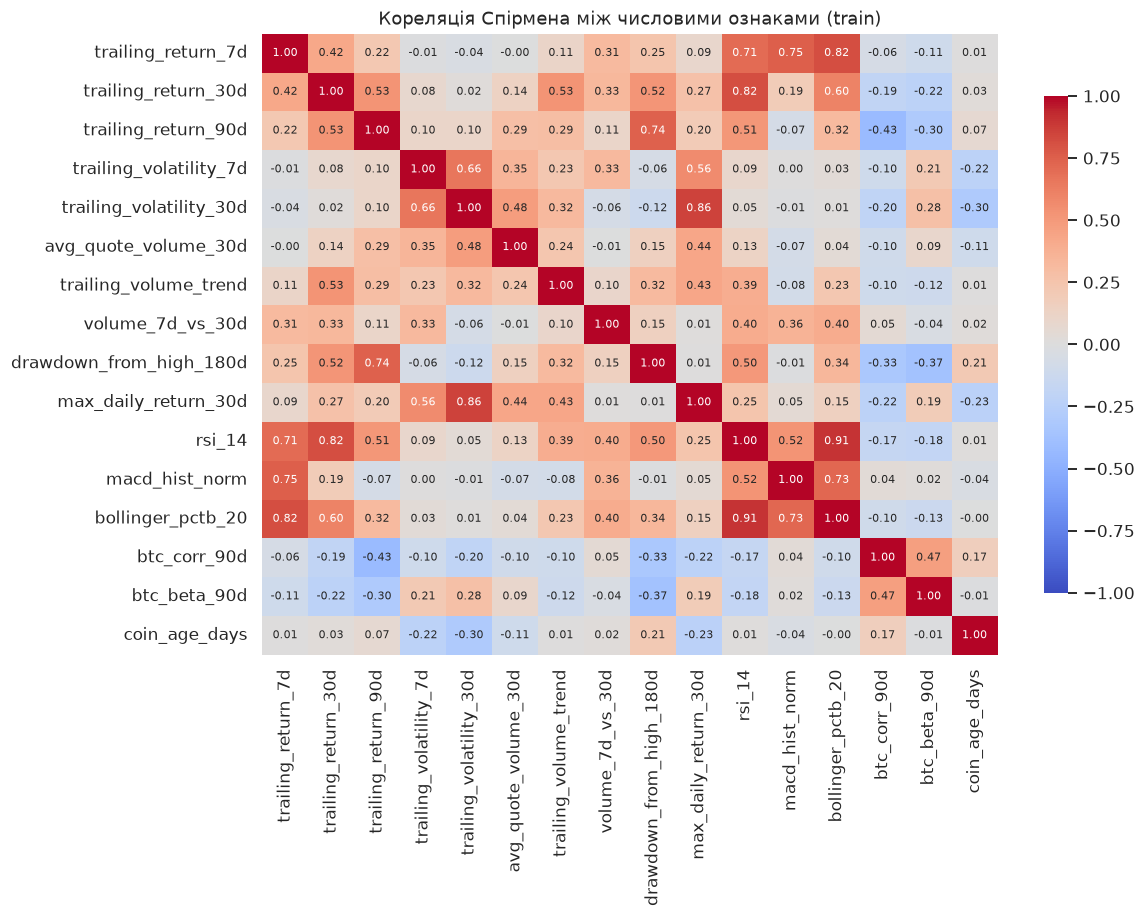

Пари з |rho| > 0,8: [('trailing_return_7d', 'bollinger_pctb_20', np.float64(0.817)), ('trailing_return_30d', 'rsi_14', np.float64(0.816)), ('trailing_volatility_30d', 'max_daily_return_30d', np.float64(0.859)), ('rsi_14', 'bollinger_pctb_20', np.float64(0.906))]


In [22]:
corr = train_df[COIN_FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Кореляція Спірмена між числовими ознаками (train)")
plt.tight_layout()
plt.show()

high = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(COIN_FEATURES)
        for b in COIN_FEATURES[i + 1:] if abs(corr.loc[a, b]) > 0.8]
print("Пари з |rho| > 0,8:", high if high else "немає")

In [23]:
rows = []
for col in COIN_FEATURES + MARKET_FEATURES:
    s = train_df[[col, "beat_market"]].dropna()
    r, p = pointbiserialr(s["beat_market"], s[col])
    rows.append({"ознака": col, "зв'язок з ціллю": round(r, 4), "p-value": f"{p:.2e}"})
for col in CAT_FEATURES:
    ct = pd.crosstab(train_df[col], train_df["beat_market"])
    chi2_c = chi2_contingency(ct)[0]
    v = np.sqrt(chi2_c / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"ознака": col, "зв'язок з ціллю": round(v, 4), "p-value": "V Крамера"})
assoc = pd.DataFrame(rows).reindex(
    pd.DataFrame(rows)["зв'язок з ціллю"].abs().sort_values(ascending=False).index)
assoc

,ознака,зв'язок з ціллю,p-value
15,coin_age_days,0.0554,5.87e-37
19,sector,0.0458,V Крамера
13,btc_corr_90d,0.0411,4.62e-21
7,volume_7d_vs_30d,-0.0369,2.70e-17
6,trailing_volume_trend,-0.0303,3.66e-12
10,rsi_14,-0.0292,2.10e-11
12,bollinger_pctb_20,-0.0271,5.26e-10
5,avg_quote_volume_30d,0.0171,9.04e-05
8,drawdown_from_high_180d,0.0066,1.30e-01
14,btc_beta_90d,-0.0060,1.70e-01


## 12. Перевірка витоку інформаціїМомент прогнозу - закриття торгів у неділю. Ознака допустима, якщо їїзначення відоме на цей момент. Стовпці, що описують майбутнє, мають бутивилучені.

In [24]:
leak_rows = []
future_cols = ["forward_return", "btc_forward_return", "market_forward_return",
               "relative_forward_return", "excess_return_vs_btc"]
service_cols = ["symbol", "coingecko_id", "checkpoint", "close_t0"]
for col in df_clean.columns:
    if col == "beat_market":
        role, reason = "ціль", "цільова змінна"
    elif col in future_cols:
        role, reason = "вилучено (витік)", "обчислюється з цін після моменту прогнозу"
    elif col in service_cols:
        role, reason = "вилучено (службовий)", "ідентифікатор або ціна, не є ознакою"
    else:
        role, reason = "ознака", "рахується лише з даних до моменту прогнозу"
    leak_rows.append({"стовпець": col, "рішення": role, "обґрунтування": reason})
leakage_table = pd.DataFrame(leak_rows)
print("Вилучено як витокові:", len(future_cols), "| як службові:", len(service_cols),
      "| залишено ознаками:", int((leakage_table["рішення"] == "ознака").sum()))
leakage_table

Вилучено як витокові: 5 | як службові: 4 | залишено ознаками: 23


,стовпець,рішення,обґрунтування
0,symbol,вилучено (службовий),"ідентифікатор або ціна, не є ознакою"
1,coingecko_id,вилучено (службовий),"ідентифікатор або ціна, не є ознакою"
2,checkpoint,вилучено (службовий),"ідентифікатор або ціна, не є ознакою"
3,sector,ознака,рахується лише з даних до моменту прогнозу
4,market_regime,ознака,рахується лише з даних до моменту прогнозу
5,close_t0,вилучено (службовий),"ідентифікатор або ціна, не є ознакою"
6,trailing_return_7d,ознака,рахується лише з даних до моменту прогнозу
7,trailing_return_30d,ознака,рахується лише з даних до моменту прогнозу
8,trailing_return_90d,ознака,рахується лише з даних до моменту прогнозу
9,trailing_volatility_7d,ознака,рахується лише з даних до моменту прогнозу


## 13. Конструювання ознакСтворено три групи кандидатних ознак. Усі вони обчислюються з величин, відомихна момент прогнозу, і не використовують цільову змінну.1. `relative_strength_vs_btc_90d` = дохідність монети за 90 днів мінус   дохідність BTC за той самий період. Предметний зміст: чи сильніша монета   за ринковий орієнтир.2. `relative_volatility_vs_market` = волатильність монети, поділена на   медіанну волатильність монет того самого тижня. Відокремлює власну   нервовість монети від загальної нервовості ринку.3. Кроссекційні ранги `*_xs`: для кожної числової ознаки береться її   процентиль серед усіх монет того самого тижня. Обґрунтування: цільова   змінна визначена відносно медіанної монети тижня, тому ознаки теж мають   бути відносними. Рівень «+5 % за 30 днів» означає різні речі на бичачому   й ведмежому ринку, а ранг серед монет того самого тижня - ні.

In [25]:
def engineer_features(d):
    d = d.copy()
    d["avg_quote_volume_30d"] = np.log1p(d["avg_quote_volume_30d"])
    d["relative_strength_vs_btc_90d"] = d["trailing_return_90d"] - d["btc_trailing_return_90d"]
    median_vol = d.groupby("checkpoint")["trailing_volatility_30d"].transform("median")
    d["relative_volatility_vs_market"] = d["trailing_volatility_30d"] / median_vol
    grouped = d.groupby("checkpoint")
    for col in COIN_FEATURES:
        d[f"{col}_xs"] = (grouped[col].rank(pct=True) - 0.5) * np.sqrt(12)
    return d


train_fe = engineer_features(train_df)
test_fe = engineer_features(test_df)

CONSTRUCTED = (["relative_strength_vs_btc_90d", "relative_volatility_vs_market"]
               + [f"{c}_xs" for c in COIN_FEATURES])
print("Створено ознак:", len(CONSTRUCTED))
train_fe[["relative_strength_vs_btc_90d", "relative_volatility_vs_market",
          "trailing_volatility_30d_xs"]].describe().T.round(4)

Створено ознак: 18


,count,mean,std,min,25%,50%,75%,max
relative_strength_vs_btc_90d,52524.0,2.0096,267.6559,-2.7946,-0.3495,-0.1871,0.0201,41043.1864
relative_volatility_vs_market,52524.0,36.5680,4097.9927,0.0000,0.8357,1.0000,1.2182,517500.9221
trailing_volatility_30d_xs,52524.0,0.0086,1.0000,-1.7219,-0.8576,0.0094,0.8746,1.7321


In [26]:
usefulness = []
for col in ["relative_strength_vs_btc_90d", "relative_volatility_vs_market",
            "trailing_volatility_30d_xs", "coin_age_days_xs", "max_daily_return_30d_xs"]:
    s = train_fe[[col, "beat_market"]].dropna()
    r, p = pointbiserialr(s["beat_market"], s[col])
    auc = roc_auc_score(s["beat_market"], s[col])
    usefulness.append({"ознака": col, "зв'язок з ціллю": round(r, 4),
                       "ROC-AUC самої ознаки": round(max(auc, 1 - auc), 4),
                       "p-value": f"{p:.2e}"})
print("Корисність сконструйованих ознак на train:")
print(pd.DataFrame(usefulness).to_string(index=False))
print()
print("Перевірка витоку: чи використовують нові ознаки майбутні величини?")
print("  relative_strength_vs_btc_90d - різниця двох трейлінгових дохідностей: ні")
print("  relative_volatility_vs_market - медіана волатильності того самого тижня: ні")
print("  *_xs - ранг серед монет того самого тижня за відомою на цей момент ознакою: ні")

Корисність сконструйованих ознак на train:
                       ознака  зв'язок з ціллю  ROC-AUC самої ознаки   p-value
 relative_strength_vs_btc_90d           0.0016                0.5169  7.20e-01
relative_volatility_vs_market          -0.0041                0.5539  3.53e-01
   trailing_volatility_30d_xs          -0.0928                0.5536 7.08e-101
             coin_age_days_xs           0.0545                0.5315  7.73e-36
      max_daily_return_30d_xs          -0.0818                0.5473  9.66e-79

Перевірка витоку: чи використовують нові ознаки майбутні величини?
  relative_strength_vs_btc_90d - різниця двох трейлінгових дохідностей: ні
  relative_volatility_vs_market - медіана волатильності того самого тижня: ні
  *_xs - ранг серед монет того самого тижня за відомою на цей момент ознакою: ні


## 14. Формування базового та фінального наборів ознак

In [27]:
BASE_NUM = COIN_FEATURES + MARKET_FEATURES
BASE_FEATURES = BASE_NUM + CAT_FEATURES

FINAL_NUM = BASE_NUM + CONSTRUCTED
FINAL_FEATURES = FINAL_NUM + CAT_FEATURES

print(f"Базовий набір: {len(BASE_FEATURES)} ознак "
      f"({len(BASE_NUM)} числових, {len(CAT_FEATURES)} категоріальних)")
print(f"Фінальний набір: {len(FINAL_FEATURES)} ознак "
      f"({len(FINAL_NUM)} числових, {len(CAT_FEATURES)} категоріальних)")
print()
print("Вилучено зі складу ознак:", future_cols + service_cols)
print()
print("Автоматичний відбір ознак за цільовою змінною не застосовується: набір із "
      "39 ознак невеликий, а надлишкові зв'язки вже перевірені в підрозділі 11.")

analytical = pd.concat([
    train_fe.assign(частина="train"), test_fe.assign(частина="test")
])[["symbol", "checkpoint", "частина"] + FINAL_FEATURES + ["beat_market"]]
analytical.to_csv("data/analytical/analytical_weekly_panel.csv.gz",
                  index=False, compression="gzip", encoding="utf-8")
print()
print("Аналітичний датасет збережено:", analytical.shape,
      "-> data/analytical/analytical_weekly_panel.csv.gz")

Базовий набір: 21 ознак (19 числових, 2 категоріальних)
Фінальний набір: 39 ознак (37 числових, 2 категоріальних)

Вилучено зі складу ознак: ['forward_return', 'btc_forward_return', 'market_forward_return', 'relative_forward_return', 'excess_return_vs_btc', 'symbol', 'coingecko_id', 'checkpoint', 'close_t0']

Автоматичний відбір ознак за цільовою змінною не застосовується: набір із 39 ознак невеликий, а надлишкові зв'язки вже перевірені в підрозділі 11.



Аналітичний датасет збережено: (65820, 43) -> data/analytical/analytical_weekly_panel.csv.gz


# Розділ 5. Препроцесинг і модельний експеримент## 15. Вибір моделі та конвеєриОбрано **HistGradientBoostingClassifier**: працює зі змішаними типами ознак,не потребує масштабування, стійкий до викидів і вловлює нелінійні залежності,яких очікуємо від ринкових даних. Базовий і фінальний конвеєри використовуютьтой самий алгоритм з однаковими гіперпараметрами; різниця лише в наборі ознакі кроках підготовки.

In [28]:
MODEL_PARAMS = dict(random_state=SEED, learning_rate=0.05, max_iter=300,
                    max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0)


def make_pipeline(numeric_features, categorical_features):
    numeric_pipeline = Pipeline([("impute", SimpleImputer(strategy="median"))])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ])
    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ])
    return Pipeline([("preprocessor", preprocessor),
                     ("model", HistGradientBoostingClassifier(**MODEL_PARAMS))])


base_pipeline = make_pipeline(BASE_NUM, CAT_FEATURES)
final_pipeline = make_pipeline(FINAL_NUM, CAT_FEATURES)
print("Гіперпараметри моделі:", MODEL_PARAMS)
print("Масштабування не додано: дерева рішень до нього нечутливі.")
print("Статистичне оброблення викидів не додано: екстремальні тижневі дохідності - "
      "реальні події ринку, а не помилки вимірювання (підрозділ 8).")

Гіперпараметри моделі: {'random_state': 42, 'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 31, 'min_samples_leaf': 200, 'l2_regularization': 1.0}
Масштабування не додано: дерева рішень до нього нечутливі.
Статистичне оброблення викидів не додано: екстремальні тижневі дохідності - реальні події ринку, а не помилки вимірювання (підрозділ 8).


## 16. Крос-валідація на trainДані часові й групові, тому звичайний перемішаний KFold дав би витік ізмайбутнього в минуле. Застосовано покрокову (walk-forward) схему зрозширюваним вікном: модель навчається на всіх тижнях до певної межі йперевіряється на наступному блоці тижнів. Між навчальною і перевірочноючастинами пропускається один тиждень (embargo), щоб семиденне вікно ціліостаннього навчального тижня не заходило в перевірочний період.

In [29]:
def walk_forward_cv(data, numeric_features, n_folds=5, embargo=1):
    weeks_all = sorted(data["checkpoint"].unique())
    start = len(weeks_all) // 2
    step = (len(weeks_all) - start) // n_folds
    results = []
    for i in range(n_folds):
        s = start + i * step
        valid_weeks = weeks_all[s:s + step] if i < n_folds - 1 else weeks_all[s:]
        train_weeks = weeks_all[:s - embargo]
        tr = data[data["checkpoint"].isin(train_weeks)]
        va = data[data["checkpoint"].isin(valid_weeks)]
        pipe = make_pipeline(numeric_features, CAT_FEATURES)
        pipe.fit(tr[numeric_features + CAT_FEATURES], tr["beat_market"])
        proba = pipe.predict_proba(va[numeric_features + CAT_FEATURES])[:, 1]
        pred = (proba >= 0.5).astype(int)
        results.append({
            "фолд": i + 1,
            "перевірка з": valid_weeks[0].date(), "по": valid_weeks[-1].date(),
            "навчання, рядків": len(tr), "перевірка, рядків": len(va),
            "ROC-AUC": roc_auc_score(va["beat_market"], proba),
            "accuracy": accuracy_score(va["beat_market"], pred),
            "F1": f1_score(va["beat_market"], pred),
        })
    return pd.DataFrame(results)


cv_base = walk_forward_cv(train_fe, BASE_NUM)
cv_final = walk_forward_cv(train_fe, FINAL_NUM)
print("Крос-валідація виконана: 5 фолдів, розширюване вікно, embargo 1 тиждень.")
cv_final.round(4)

Крос-валідація виконана: 5 фолдів, розширюване вікно, embargo 1 тиждень.


,фолд,перевірка з,по,"навчання, рядків","перевірка, рядків",ROC-AUC,accuracy,F1
0,1,2023-07-09,2023-12-31,19565,5291,0.5203,0.5131,0.5076
1,2,2024-01-07,2024-06-30,24844,5670,0.5685,0.5459,0.5566
2,3,2024-07-07,2024-12-29,30492,6293,0.5606,0.5381,0.5481
3,4,2025-01-05,2025-06-29,36765,6989,0.5483,0.5354,0.5591
4,5,2025-07-06,2026-01-04,43718,8518,0.5552,0.5405,0.5826


In [30]:
comparison = pd.DataFrame([
    {"конвеєр": "Базовий", "ROC-AUC, середнє": cv_base["ROC-AUC"].mean(),
     "ROC-AUC, std": cv_base["ROC-AUC"].std(), "accuracy": cv_base["accuracy"].mean(),
     "F1": cv_base["F1"].mean()},
    {"конвеєр": "Фінальний", "ROC-AUC, середнє": cv_final["ROC-AUC"].mean(),
     "ROC-AUC, std": cv_final["ROC-AUC"].std(), "accuracy": cv_final["accuracy"].mean(),
     "F1": cv_final["F1"].mean()},
]).round(4)
print("Порівняння конвеєрів на крос-валідації (train):")
print(comparison.to_string(index=False))
print()
print("Фінальний кращий за базовий на",
      round((cv_final['ROC-AUC'].mean() - cv_base['ROC-AUC'].mean()), 4), "ROC-AUC;")
print("виграш дають саме сконструйовані ознаки, бо алгоритм і гіперпараметри однакові.")

Порівняння конвеєрів на крос-валідації (train):
  конвеєр  ROC-AUC, середнє  ROC-AUC, std  accuracy     F1
  Базовий            0.5452        0.0142    0.5337 0.5584
Фінальний            0.5506        0.0185    0.5346 0.5508

Фінальний кращий за базовий на 0.0054 ROC-AUC;
виграш дають саме сконструйовані ознаки, бо алгоритм і гіперпараметри однакові.


## 17. Фінальне навчання та одноразове тестуванняФінальний конвеєр навчається на всьому train, після чого test використовуєтьсярівно один раз. Структура конвеєра після перегляду результатів не змінюється.

In [31]:
X_train, y_train = train_fe[FINAL_FEATURES], train_fe["beat_market"]
X_test, y_test = test_fe[FINAL_FEATURES], test_fe["beat_market"]

final_pipeline.fit(X_train, y_train)
y_proba = final_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

test_metrics = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, y_proba),
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
}).round(4)
print("Метрики фінального конвеєра на test:")
print(test_metrics.to_string())

Метрики фінального конвеєра на test:
ROC-AUC              0.5521
Accuracy             0.5369
Balanced accuracy    0.5369
Precision            0.5344
Recall               0.5665
F1                   0.5500


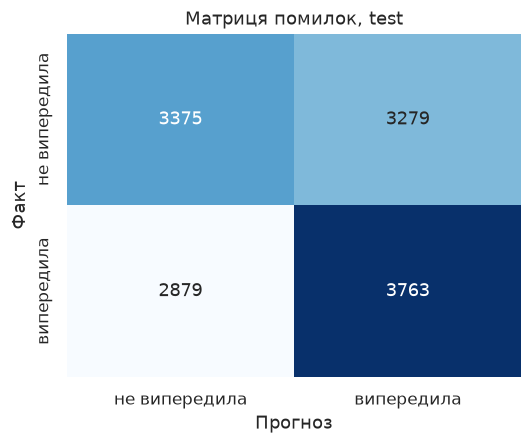

               precision    recall  f1-score   support

не випередила       0.54      0.51      0.52      6654
   випередила       0.53      0.57      0.55      6642

     accuracy                           0.54     13296
    macro avg       0.54      0.54      0.54     13296
 weighted avg       0.54      0.54      0.54     13296



In [32]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["не випередила", "випередила"],
            yticklabels=["не випередила", "випередила"], ax=ax)
ax.set_title("Матриця помилок, test")
ax.set_xlabel("Прогноз")
ax.set_ylabel("Факт")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=["не випередила", "випередила"]))

In [33]:
test_eval = test_fe.assign(correct=(y_pred == y_test).values, proba=y_proba)
by_sector = test_eval.groupby("sector")["correct"].agg(["mean", "count"]).rename(
    columns={"mean": "точність", "count": "спостережень"})
by_regime = test_eval.groupby("market_regime").apply(
    lambda g: pd.Series({"ROC-AUC": roc_auc_score(g["beat_market"], g["proba"]),
                         "точність": g["correct"].mean(),
                         "спостережень": len(g)}))
print("Якість за ринковим режимом тижня (test):")
print(by_regime.round(4).to_string())
print()
print("Точність за секторами (test), п'ять найгірших і п'ять найкращих:")
print(pd.concat([by_sector.nsmallest(5, "точність"),
                 by_sector.nlargest(5, "точність")]).round(4).to_string())

Якість за ринковим режимом тижня (test):
               ROC-AUC  точність  спостережень
market_regime                                 
bear            0.5506    0.5339        9156.0
bull            0.6032    0.5731        1881.0
sideways        0.5155    0.5188        2259.0

Точність за секторами (test), п'ять найгірших і п'ять найкращих:
                  точність  спостережень
sector                                  
RWA                 0.4894           613
Privacy             0.4907           108
Metaverse/Gaming    0.5000            72
DeFi                0.5016          1547
Other               0.5202          2007
Exchange Token      0.6111            72
Stablecoin          0.5826           218
Layer-2             0.5752           798
Oracle/Infra        0.5588           374
Infrastructure      0.5585           410


In [34]:
dummy = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy.fit(X_train, y_train)
dummy_auc = roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1])

base_pipeline.fit(train_fe[BASE_FEATURES], y_train)
base_test_auc = roc_auc_score(y_test, base_pipeline.predict_proba(test_fe[BASE_FEATURES])[:, 1])

summary = pd.DataFrame({
    "етап": ["Наївний класифікатор", "Базовий конвеєр, крос-валідація",
             "Фінальний конвеєр, крос-валідація", "Базовий конвеєр, test",
             "Фінальний конвеєр, test"],
    "ROC-AUC": [dummy_auc, cv_base["ROC-AUC"].mean(), cv_final["ROC-AUC"].mean(),
                base_test_auc, test_metrics["ROC-AUC"]],
}).round(4)
print(summary.to_string(index=False))

                             етап  ROC-AUC
             Наївний класифікатор   0.5000
  Базовий конвеєр, крос-валідація   0.5452
Фінальний конвеєр, крос-валідація   0.5506
            Базовий конвеєр, test   0.5370
          Фінальний конвеєр, test   0.5521


## 18. Практична перевірка на тестовому періодіМетрика ROC-AUC показує якість ранжування, але не показує, чи має вонапрактичний сенс. Тому на тестовому періоді змодельовано просте правило: щотижнябереться 20 % монет з найвищим прогнозом, і порівнюється їхня фактичнадохідність із медіанною монетою ринку та з біткоїном. Модель навчена лише наtrain і під час цієї перевірки не перенавчається.

In [35]:
weekly_rows = []
for cp, g in test_eval.groupby("checkpoint"):
    k = max(1, int(round(len(g) * 0.2)))
    top = g.nlargest(k, "proba")
    bottom = g.nsmallest(k, "proba")
    weekly_rows.append({
        "checkpoint": cp,
        "топ-20 %": top["forward_return"].mean(),
        "нижні 20 %": bottom["forward_return"].mean(),
        "медіанна монета": g["forward_return"].median(),
        "BTC": g["btc_forward_return"].iloc[0],
    })
weekly = pd.DataFrame(weekly_rows).set_index("checkpoint")
weekly["топ мінус нижні"] = weekly["топ-20 %"] - weekly["нижні 20 %"]

print(f"Тестовий період: {weekly.index.min().date()} - {weekly.index.max().date()}, "
      f"{len(weekly)} тижнів")
print()
print("Середня дохідність за тиждень, %:")
print((weekly.mean() * 100).round(2).to_string())
print()
print("Частка тижнів у плюсі:")
print((weekly > 0).mean().round(3).to_string())

Тестовий період: 2026-01-11 - 2026-09-13, 36 тижнів

Середня дохідність за тиждень, %:
топ-20 %           0.43
нижні 20 %        -0.87
медіанна монета   -1.90
BTC               -0.11
топ мінус нижні    1.30

Частка тижнів у плюсі:
топ-20 %           0.500
нижні 20 %         0.472
медіанна монета    0.361
BTC                0.472
топ мінус нижні    0.667


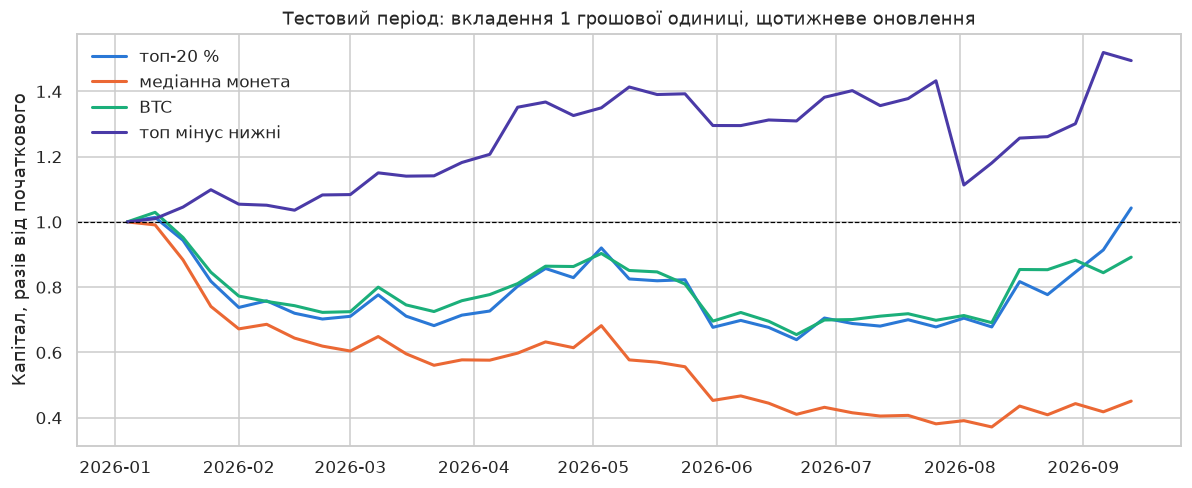

Підсумок за весь тестовий період, разів від початкового капіталу:
топ-20 %           1.043
медіанна монета    0.451
BTC                0.892
топ мінус нижні    1.494


In [36]:
equity = (1 + weekly[["топ-20 %", "медіанна монета", "BTC", "топ мінус нижні"]]).cumprod()
equity.loc[weekly.index.min() - pd.Timedelta(days=7)] = 1.0
equity = equity.sort_index()

fig, ax = plt.subplots(figsize=(11, 4.6))
colors = {"топ-20 %": "#2a78d6", "медіанна монета": "#eb6834",
          "BTC": "#1baf7a", "топ мінус нижні": "#4a3aa7"}
for col, color in colors.items():
    ax.plot(equity.index, equity[col], label=col, color=color, linewidth=2)
ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--")
ax.set_ylabel("Капітал, разів від початкового")
ax.set_title("Тестовий період: вкладення 1 грошової одиниці, щотижневе оновлення")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print("Підсумок за весь тестовий період, разів від початкового капіталу:")
print(equity.iloc[-1].round(3).to_string())

## 19. Чому протокол перевірки важливийТой самий конвеєр, перевірений на даних, на яких він навчався, показуєзначно кращий результат. Це не покращення моделі, а вимірювання її пам'яті,і саме так з'являються нереалістичні оцінки якості.

In [37]:
in_sample_proba = final_pipeline.predict_proba(X_train)[:, 1]
print("ROC-AUC на train (модель бачила ці дані):",
      round(roc_auc_score(y_train, in_sample_proba), 4))
print("ROC-AUC на test (чесна оцінка):       ", round(test_metrics["ROC-AUC"], 4))
print()
print("Різниця показує розмір «пам'яті» моделі. Будь-яка оцінка якості, отримана "
      "на даних навчання, завищена і не може використовуватись як результат.")

ROC-AUC на train (модель бачила ці дані): 0.7556
ROC-AUC на test (чесна оцінка):        0.5521

Різниця показує розмір «пам'яті» моделі. Будь-яка оцінка якості, отримана на даних навчання, завищена і не може використовуватись як результат.


## 20. Підсумкові висновкиРезультати цього notebook перенесено в текстову частину курсової роботи:характеристика датасету, знайдені проблеми якості та правила очищення,результати двох перевірок гіпотез, аналіз залежностей і витоку,сконструйовані ознаки, порівняння базового й фінального конвеєрів накрос-валідації, одноразовий результат на test і практична перевірка.